# Setup

In [1]:
!nvidia-smi

Sat Oct 24 22:44:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   29C    P0             44W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
from google.colab import drive
drive.mount('/content/drive')


import os
DRIVE_ROOT = '/content/drive/MyDrive/stylessp'
CKPT_DIR   = f'{DRIVE_ROOT}/checkpoints'
HF_CACHE   = f'{DRIVE_ROOT}/hf_cache'
REPO_DIR   = '/content/StyleSSP'

for d in [DRIVE_ROOT, CKPT_DIR, HF_CACHE]:
    os.makedirs(d, exist_ok=True)


os.environ['HF_HOME'] = HF_CACHE

Mounted at /content/drive


fresh copy for every session, and symlink to drive folder

In [4]:

!rm -rf {REPO_DIR}
!git clone https://github.com/Michael-Boat-2/StyleSSP {REPO_DIR}
%cd {REPO_DIR}
!git log --oneline -1

!ln -sfn {CKPT_DIR} {REPO_DIR}/checkpoints

Cloning into '/content/StyleSSP'...
remote: Enumerating objects: 97, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 97 (delta 18), reused 19 (delta 12), pack-reused 65 (from 1)
Receiving objects: 100% (97/97), 2.53 MiB | 13.64 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/StyleSSP
487c167 (HEAD -> main, origin/main, origin/HEAD) sanity check run


Installing Pinned Libraries

In [11]:
!pip install -q uv
!uv venv /content/venv --python 3.9
!uv pip install --python /content/venv/bin/python -r requirements.txt
!uv pip install --python /content/venv/bin/python git+https://github.com/openai/CLIP.git

!/content/venv/bin/python -c "import torch, diffusers, transformers; print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '| diffusers', diffusers.__version__, '| transformers', transformers.__version__)"

Using CPython 3.9.25
Creating virtual environment at: /content/venv
Activate with: source /content/venv/bin/activate
Using Python 3.9.25 environment at: /content/venv
Resolved 91 packages in 575ms
Prepared 91 packages in 3m 30s
Installed 91 packages in 203ms
 + accelerate==0.33.0
 + certifi==2024.7.4
 + cffi==1.17.0
 + charset-normalizer==3.3.2
 + contourpy==1.3.0
 + controlnet-aux==0.0.9
 + cycler==0.12.1
 + diffusers==0.30.0
 + distlib==0.4.4
 + einops==0.8.0
 + entrypoints==0.4.2
 + executing==2.0.1
 + filelock==3.15.4
 + fonttools==4.54.0
 + fsspec==2024.6.1
 + ftfy==6.2.3
 + hf-transfer==0.1.8
 + huggingface-hub==0.24.5
 + idna==3.7
 + imageio==2.35.1
 + importlib-metadata==8.2.0
 + importlib-resources==6.4.5
 + jinja2==3.1.4
 + joblib==1.4.2
 + jupyter-client==7.4.9
 + jupyter-core==5.8.1
 + kiwisolver==1.4.7
 + lazy-loader==0.4
 + lpips==0.1.4
 + markupsafe==2.1.5
 + matplotlib==3.7.1
 + mpmath==1.3.0
 + mypy-extensions==1.0.0
 + nest-asyncio==1.6.0
 + networkx==3.2.1
 + numpy==

Downloading Checkpoints

In [12]:
from huggingface_hub import snapshot_download, hf_hub_download

# IP-Adapter:  SDXL weights file for style injection during sampling
snapshot_download('h94/IP-Adapter', local_dir=f'{CKPT_DIR}/IP-Adapter',
                  allow_patterns=['sdxl_models/ip-adapter_sdxl_vit-h.safetensors'])

# ControlNets (control_type = 'tile_canny' in config.py) : content preservation during sampling
snapshot_download('xinsir/controlnet-tile-sdxl-1.0', local_dir=f'{CKPT_DIR}/controlnet-tile-sdxl-1.0',
                  allow_patterns=['config.json', '*.safetensors'])
snapshot_download('TheMistoAI/MistoLine', local_dir=f'{CKPT_DIR}/MistoLine',
                  allow_patterns=['config.json', '*.fp16.safetensors'])

# IP-Adapter-Instruct: the content/style extractor behind negative guidance
hf_hub_download('CiaraRowles/IP-Adapter-Instruct', 'ip-adapter-instruct-sdxl.bin',
                local_dir=f'{CKPT_DIR}/models')

!du -sh {CKPT_DIR}/*

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

2.4G	/content/drive/MyDrive/stylessp/checkpoints/controlnet-tile-sdxl-1.0
667M	/content/drive/MyDrive/stylessp/checkpoints/IP-Adapter
2.4G	/content/drive/MyDrive/stylessp/checkpoints/MistoLine
2.0G	/content/drive/MyDrive/stylessp/checkpoints/models


Recording the used environment for the reproduction

In [13]:
!/content/venv/bin/python --version > {REPO_DIR}/repro/env/colab_freeze.txt
!uv pip freeze --python /content/venv/bin/python >> {REPO_DIR}/repro/env/colab_freeze.txt

Using Python 3.9.25 environment at: /content/venv


In [14]:
# test pair for our config

CONTENT = f'{DRIVE_ROOT}/test_images/content.jpg'
STYLE   = f'{DRIVE_ROOT}/test_images/style.jpg'

!sed -i "s|style_image_dir = .*|style_image_dir = '{STYLE}'|" src/config.py
!sed -i "s|content_image_dir = .*|content_image_dir = '{CONTENT}'|" src/config.py
!grep -n "image_dir" src/config.py

66:    style_image_dir = '/content/drive/MyDrive/stylessp/test_images/style.jpg'
67:    content_image_dir = '/content/drive/MyDrive/stylessp/test_images/content.jpg'


In [15]:
%%time
!/content/venv/bin/python infer_style.py

A matching Triton is not available, some optimizations will not be enabled
Traceback (most recent call last):
  File "/content/venv/lib/python3.9/site-packages/xformers/__init__.py", line 55, in _is_triton_available
    from xformers.triton.softmax import softmax as triton_softmax  # noqa
  File "/content/venv/lib/python3.9/site-packages/xformers/triton/softmax.py", line 11, in <module>
    import triton
  File "/content/venv/lib/python3.9/site-packages/triton/__init__.py", line 8, in <module>
    from .runtime import (
  File "/content/venv/lib/python3.9/site-packages/triton/runtime/__init__.py", line 1, in <module>
    from .autotuner import (Autotuner, Config, Heuristics, OutOfResources, autotune, heuristics)
  File "/content/venv/lib/python3.9/site-packages/triton/runtime/autotuner.py", line 7, in <module>
    from ..testing import do_bench
  File "/content/venv/lib/python3.9/site-packages/triton/testing.py", line 8, in <module>
    from . import language as tl
  File "/content/ven

results/ours_content_style.png


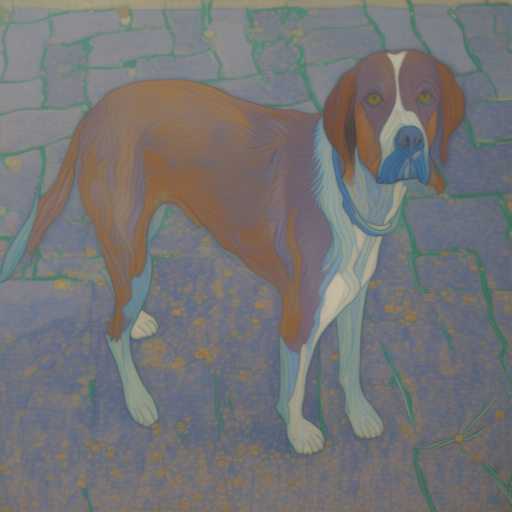

In [16]:
from IPython.display import display
from PIL import Image
import glob, shutil

for p in sorted(glob.glob('results/*.png')):
    print(p)
    display(Image.open(p).resize((512, 512)))
    shutil.copy(p, f'{DRIVE_ROOT}/')